# 02 Choose the scope

The data covers 10 stores in three states and 3,049 products. We cannot study every series well, so here we decide
which ones we look at: California only, one series per product (the four stores added up), and only products that
sell a lot and fairly steadily. This notebook writes the daily sales of those 726 products, which every later
notebook starts from.

## Load

In [1]:
import sys
sys.path.append("../src")
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import pandas as pd
import matplotlib.pyplot as plt

from config import ROOT, RAW, INTERIM, FIGS, CATEGORIES
from segmentation import trim_leading_zeros, scope_and_aggregate, abc_xyz_segment
from diagnostics import run_adf_tests
from pipeline import count_leading_zero_items

INTERIM.mkdir(parents=True, exist_ok=True)
written = []
sales = pd.read_csv(RAW / "sales_train_evaluation.csv")
cal = pd.read_csv(RAW / "calendar.csv")
cal["date"] = pd.to_datetime(cal["date"])

## California only

We keep California because it has the most stores (4 of the 10), so its summed series are the smoothest. Texas and
Wisconsin come back at the very end, in `11f_texas_and_wisconsin`, to check that what we find here also holds there.

In [2]:
ca = sales[sales["state_id"] == "CA"]
print(f"{len(ca):,} store-product rows in California, {ca['item_id'].nunique():,} products, stores: {sorted(ca['store_id'].unique())}")
print(ca.groupby("cat_id")["item_id"].nunique().to_dict())

12,196 store-product rows in California, 3,049 products, stores: ['CA_1', 'CA_2', 'CA_3', 'CA_4']
{'FOODS': 1437, 'HOBBIES': 565, 'HOUSEHOLD': 1047}


## One series per product, trimmed, then split into ABC-XYZ groups

For each category we add the four stores together, cut off the zeros before each product's first sale
(`04_zeros_and_trimming` shows why those zeros would mislead us), and then classify products two ways. ABC ranks them
by units sold: A is the top 70% of the category's volume, B the next 20%, C the rest. XYZ ranks them by how much daily
sales vary (coefficient of variation): X below 0.5, Y up to 1.0, Z above. We keep AX and AY: high volume, and
predictable enough to forecast.

Our first try counted a product as having a "leading zero problem" if it sold nothing on day 1. That gave 775
FOODS products, but many of those were just slow on one day. Counting only products whose first sale comes after
more than 30 days gives 714, and that is the number we use.

In [3]:
summary, long_by_cat, stats_by_cat, kept = {}, {}, {}, {}
for cat in CATEGORIES:
    items, day_cols = scope_and_aggregate(sales, "CA", cat)
    df = items.melt(id_vars="item_id", var_name="d", value_name="sales").merge(cal[["d", "date"]], on="d", how="left")
    n_before = len(df)
    df = trim_leading_zeros(df)
    seg = abc_xyz_segment(df)
    keep = seg[seg["segment"].isin(["AX", "AY"])]["item_id"].tolist()
    adf = run_adf_tests(df, keep)

    df[df["item_id"].isin(keep)].to_csv(INTERIM / f"{cat.lower()}_candidates.csv", index=False)
    seg.to_csv(INTERIM / f"{cat.lower()}_segmentation.csv", index=False)
    adf.to_csv(INTERIM / f"{cat.lower()}_adf_results.csv", index=False)
    written += [INTERIM / f"{cat.lower()}_{x}" for x in ["candidates.csv", "segmentation.csv", "adf_results.csv"]]

    long_by_cat[cat], stats_by_cat[cat], kept[cat] = df, seg, keep
    summary[cat] = {"total_items": len(items), "items_with_leading_zeros": count_leading_zero_items(items, day_cols),
                    "pct_items_with_leading_zeros": round(count_leading_zero_items(items, day_cols) / len(items) * 100, 1),
                    "ax_ay_candidates": len(keep), "items_tested": len(adf),
                    "pct_stationary": round(adf["is_stationary"].mean() * 100, 1)}
    print(f"{cat}: {len(items)} products, rows {n_before:,} -> {len(df):,} after trimming, {len(keep)} AX/AY")

summary = pd.DataFrame(summary).T.astype(float)
summary.to_csv(INTERIM / "cross_category_summary.csv")
written.append(INTERIM / "cross_category_summary.csv")
summary

FOODS: 1437 products, rows 2,789,217 -> 2,279,871 after trimming, 337 AX/AY


HOBBIES: 565 products, rows 1,096,665 -> 897,469 after trimming, 106 AX/AY


HOUSEHOLD: 1047 products, rows 2,032,227 -> 1,657,048 after trimming, 283 AX/AY


,total_items,items_with_leading_zeros,pct_items_with_leading_zeros,ax_ay_candidates,items_tested,pct_stationary
FOODS,1437.0,714.0,49.7,337.0,337.0,85.2
HOBBIES,565.0,303.0,53.6,106.0,106.0,87.7
HOUSEHOLD,1047.0,548.0,52.3,283.0,283.0,83.4


## Why AX and AY

In [4]:
for cat, seg in stats_by_cat.items():
    ax_ay = seg["segment"].isin(["AX", "AY"])
    print(f"{cat:9s} AX/AY: {ax_ay.mean():5.1%} of products, {seg.loc[ax_ay, 'total_sales'].sum() / seg['total_sales'].sum():.1%} of units")
pd.concat({c: s["segment"].value_counts() for c, s in stats_by_cat.items()}, axis=1).fillna(0).astype(int)

FOODS     AX/AY: 23.5% of products, 66.4% of units
HOBBIES   AX/AY: 18.8% of products, 63.6% of units
HOUSEHOLD AX/AY: 27.0% of products, 67.6% of units


,FOODS,HOBBIES,HOUSEHOLD
segment,,,
CZ,364,254,370
BY,363,113,239
CY,281,27,69
AY,280,100,240
BZ,66,52,69
AX,57,6,43
AZ,23,13,15
BX,3,0,2


## Enough data in every series?

A seasonal model needs to see many weeks, and our backtest needs two years of history before its first forecast.
We ask for at least 500 days per series.

In [5]:
n_days = pd.concat([long_by_cat[c][long_by_cat[c]["item_id"].isin(kept[c])] for c in CATEGORIES])
n_days = n_days.groupby("item_id").size()
print(f"{len(n_days)} kept products; shortest series {n_days.min()} days, median {n_days.median():.0f}, "
      f"fewer than 500 days: {(n_days < 500).sum()}, fewer than 730: {(n_days < 730).sum()}")
assert (n_days >= 500).all()

726 kept products; shortest series 508 days, median 1941, fewer than 500 days: 0, fewer than 730: 6


## A look at one product per category

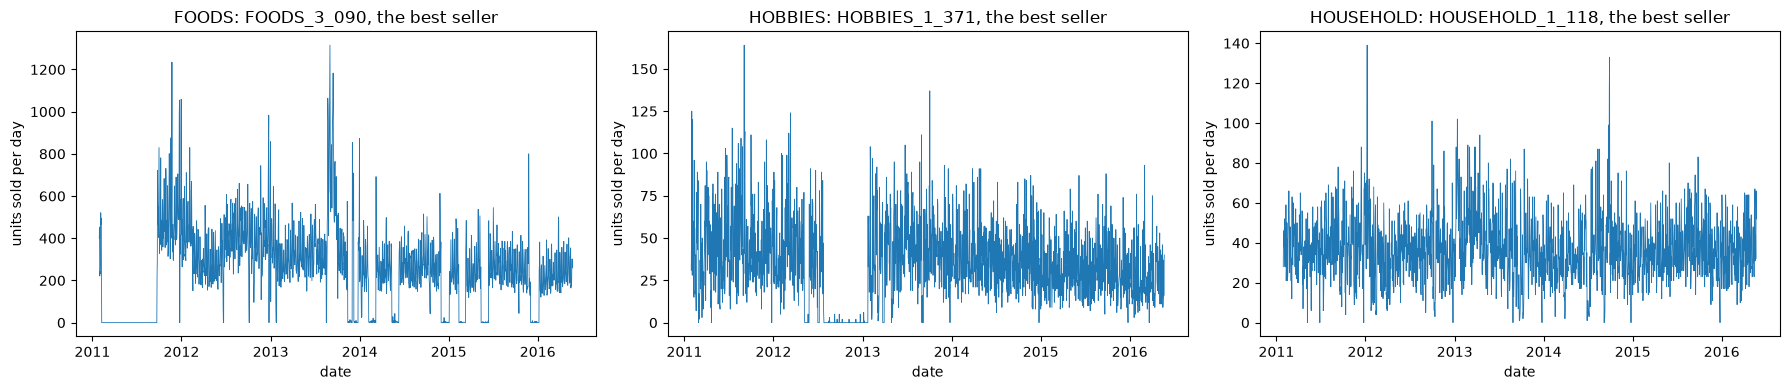

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, cat in zip(axes, CATEGORIES):
    top = stats_by_cat[cat].iloc[0]["item_id"]          # the category's best seller
    s = long_by_cat[cat][long_by_cat[cat]["item_id"] == top].sort_values("date")
    ax.plot(s["date"], s["sales"], lw=0.6)
    ax.set_title(f"{cat}: {top}, the best seller")
    ax.set_xlabel("date")
    ax.set_ylabel("units sold per day")
plt.tight_layout()
plt.savefig(FIGS / "cross_category_sample_series.png")
written.append(FIGS / "cross_category_sample_series.png")
plt.show()

## What we found

California has 3,049 products: 1,437 FOODS, 565 HOBBIES and 1,047 HOUSEHOLD. Trimming the zeros before each first
sale removes about 18% of all rows in every category. After that, 726 products are AX or AY: 337 FOODS, 106 HOBBIES
and 283 HOUSEHOLD. They are only about a quarter of the products but carry about two thirds of the units sold
(66.4% for FOODS, 63.6% for HOBBIES, 67.6% for HOUSEHOLD), so they are the ones a store most needs to forecast well.

Every kept series has at least 508 days, so the 500-day check passes for all of them. Six have fewer than 730 days,
which matters later because the classical models train on the last 730 days.

The best sellers show what is coming: strong day-to-day swings, spikes, and runs of zeros in the middle of a series
(FOODS_3_090 sells hundreds a day and then nothing for over a week, probably a stockout). We keep those middle
zeros, because they are real.

## What comes next

`03_explore` looks at these 726 series more closely: their size, their weekly and yearly rhythm, and what moves with them.

In [7]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

data\interim\foods_candidates.csv 20,189 KB
data\interim\foods_segmentation.csv 143 KB
data\interim\foods_adf_results.csv 20 KB
data\interim\hobbies_candidates.csv 6,732 KB
data\interim\hobbies_segmentation.csv 58 KB
data\interim\hobbies_adf_results.csv 6 KB
data\interim\household_candidates.csv 17,941 KB
data\interim\household_segmentation.csv 109 KB
data\interim\household_adf_results.csv 18 KB
data\interim\cross_category_summary.csv 0 KB
outputs\figures\cross_category_sample_series.png 127 KB
